# **SMS SPAM CLASSIFIER**


In [1]:
import numpy as np
import pandas as pd


In [2]:
df=pd.read_csv("spam.csv",encoding="latin-1")

In [3]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3071,ham,Ok lor... But buy wat?,NaN,NaN,NaN
3397,ham,It only does simple arithmetic not percentages.,NaN,NaN,NaN
2910,ham,"Sorry,in meeting I'll call later",NaN,NaN,NaN
758,ham,U should have made an appointment,NaN,NaN,NaN
639,ham,I had askd u a question some hours before. Its...,NaN,NaN,NaN


In [4]:
df.shape

(5572, 5)

# DATA CLEANING

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
#drop last 3 columns
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)
df.sample(5)

,v1,v2
9,spam,Had your mobile 11 months or more? U R entitle...
2293,ham,Hello. Damn this christmas thing. I think i ha...
1029,ham,"Its good, we'll find a way"
1011,ham,"I just got home babe, are you still awake ?"
3448,ham,Sorry. || mail? ||


In [7]:
#renaming the columns
df.rename(columns={'v1':'Target','v2':'Text'},inplace=True)
df.sample(5)

,Target,Text
4024,ham,&lt;#&gt; in mca. But not conform.
2950,ham,Hey now am free you can call me.
4866,ham,Okey dokey swashbuckling stuff what oh.
2470,ham,Eat at old airport road... But now 630 oredi.....
239,spam,U 447801259231 have a secret admirer who is lo...


In [8]:
#label encoding
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

In [9]:
df['Target']=encoder.fit_transform(df['Target'])

In [10]:
df.head()

,Target,Text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
#missing values
df.isnull().sum()

Target    0
Text      0
dtype: int64

In [12]:
#duplicate value
df.duplicated().sum()

403

In [13]:
#drop duplicate values
df=df.drop_duplicates(keep='first')
df.shape

(5169, 2)

# EDA

In [14]:
df.head()

,Target,Text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [15]:
df['Target'].value_counts()

Target
0    4516
1     653
Name: count, dtype: int64

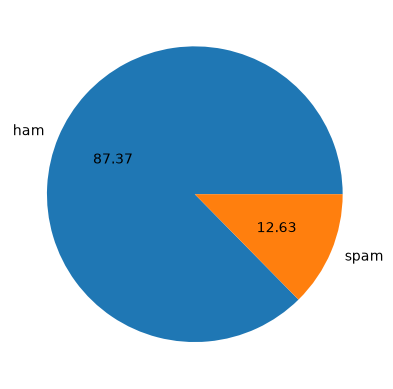

In [16]:
import matplotlib.pyplot as plt
plt.pie(df['Target'].value_counts(),labels=['ham','spam'],autopct='%0.2f')
plt.show()

In [17]:
#data is imbalanced

In [18]:
!pip install nltk


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import nltk

In [20]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


False

In [21]:
# number of characters
df['num_characters']=df['Text'].apply(len)
df.head()

,Target,Text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [22]:
# number of words
df['num_words']=df['Text'].apply(lambda x:len(nltk.word_tokenize(x)))
df.head()

,Target,Text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [23]:
# number of sentences
df['num_sentences']=df['Text'].apply(lambda x:len(nltk.sent_tokenize(x)))
df.head()

,Target,Text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [24]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
#ham messages
df[df['Target']==0][['num_characters','num_words','num_sentences']].describe()  ##imp

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [26]:
# spam messages
df[df['Target']==1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_characters', ylabel='Count'>

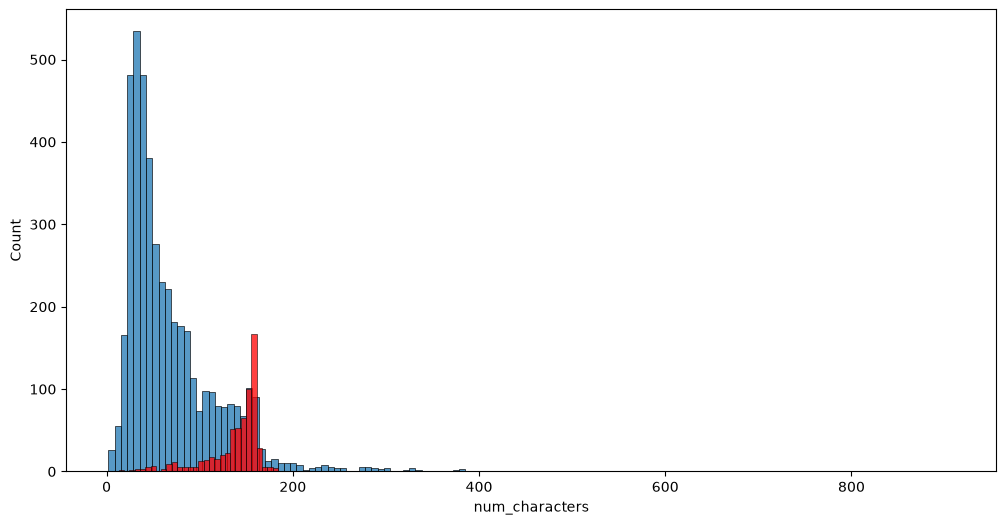

In [27]:
import seaborn as sns
plt.figure(figsize=(12,6))
sns.histplot(df[df['Target']==0]['num_characters'])
sns.histplot(df[df['Target']==1]['num_characters'],color='red')

<Axes: xlabel='num_words', ylabel='Count'>

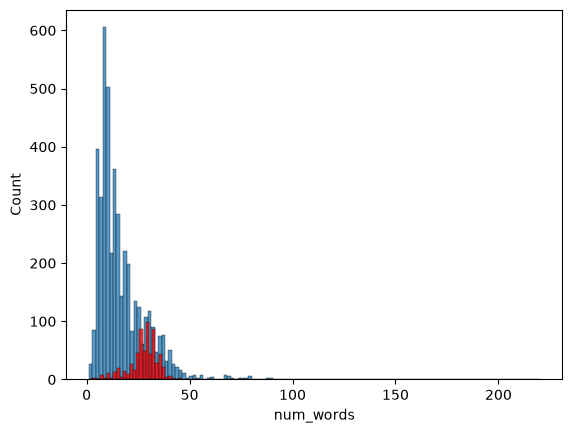

In [28]:
sns.histplot(df[df['Target']==0]['num_words'])
sns.histplot(df[df['Target']==1]['num_words'],color='red')

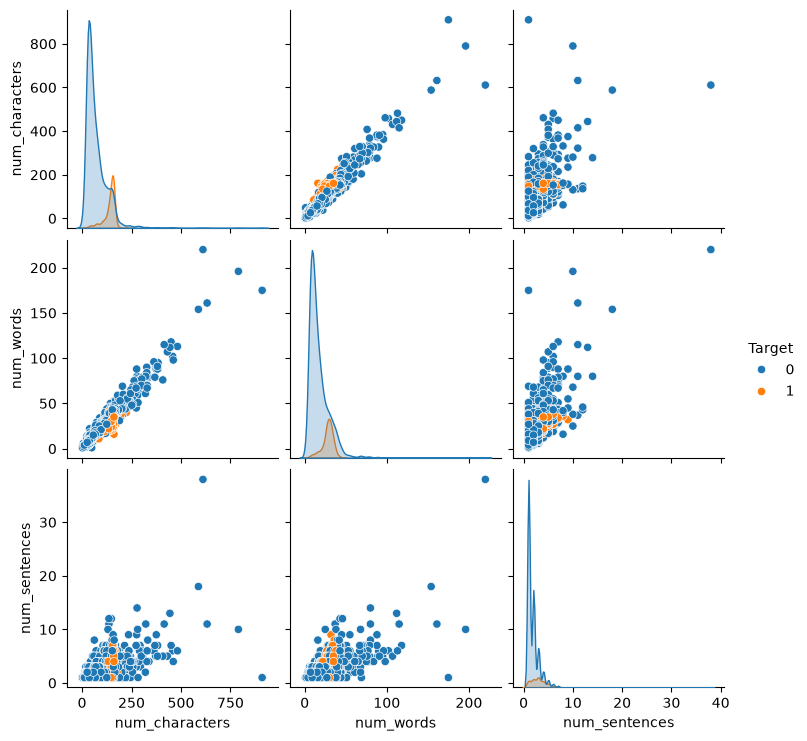

In [29]:
sns.pairplot(df,hue='Target')

In [30]:
#df.corr()

In [31]:
print(df.dtypes)


Target             int32
Text              object
num_characters     int64
num_words          int64
num_sentences      int64
dtype: object


<Axes: >

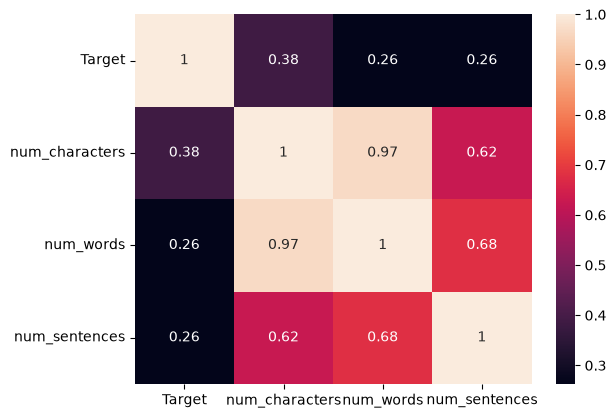

In [32]:
sns.heatmap(df.corr(numeric_only=True),annot=True)


# DATA PREPROCESSING
1.lowercase
2.tokenization
3.removing special characters
4.removing stop words and punctuation
5.lemmatization


In [33]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

In [34]:
import string
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [35]:
from nltk.stem.porter import PorterStemmer
ps=PorterStemmer()
ps.stem('dancing')

'danc'

In [36]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

In [37]:
import unicodedata
def normalize_accents(text):
    return ''.join(
        c for c in unicodedata.normalize('NFKD', text)
        if not unicodedata.combining(c)
    )

In [38]:
import re
def transform_text(text):
    text = normalize_accents(text)
    # Replace URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    # Replace phone numbers (7+ consecutive digits)
    text = re.sub(r'\b\d{7,}\b', ' PHONE_NUMBER ', text)
    # Replace money amounts (£, $, ₹ followed by numbers)
    text = re.sub(r'[£$₹]\s*\d+', ' MONEY ', text)
    text=text.lower()
    text=nltk.word_tokenize(text)
    y=[]
    for i in text:
        if i.isalnum():
             y.append(i)
    temp =[]
    for i in y:
        if i not in stop_words and i not in string.punctuation:
            temp.append(i)

    y = []
    for i in temp:
         y.append(lemmatizer.lemmatize(i))

    return " ".join(y)

In [39]:
transform_text('hEhLoOLo hOw aRE you 2005%%% ***')

'hehloolo 2005'

In [40]:
transform_text(df['Text'][2000])

'b going 2 sch mon si need 2 take smth'

In [41]:
df['trans_text']=df['Text'].apply(transform_text)
df.head()

,Target,Text,num_characters,num_words,num_sentences,trans_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entry 2 wkly comp win fa cup final tkts 2...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think go usf life around though


In [42]:
!pip install WordCloud
from wordcloud import WordCloud
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
spam_wc=wc.generate(df[df['Target']==1]['trans_text'].str.cat(sep=' '))

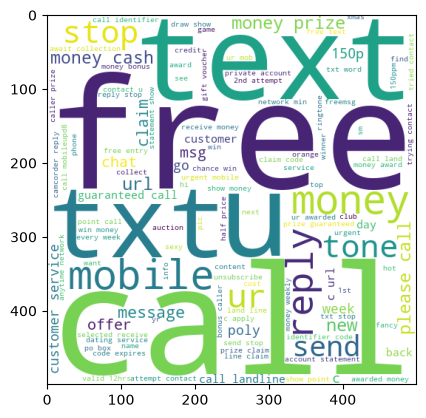

In [44]:
plt.imshow(spam_wc)

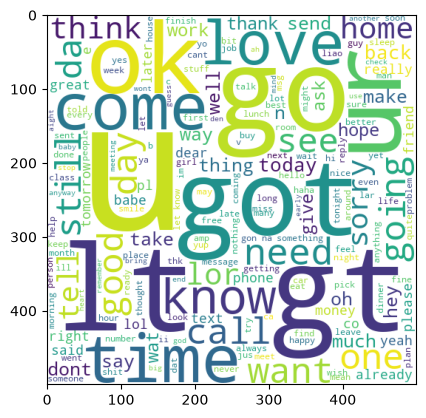

In [45]:
ham_wc=wc.generate(df[df['Target']==0]['trans_text'].str.cat(sep=' '))
plt.imshow(ham_wc)

In [46]:
df.head()

,Target,Text,num_characters,num_words,num_sentences,trans_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entry 2 wkly comp win fa cup final tkts 2...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think go usf life around though


In [47]:
df[df['Target']==1]

,Target,Text,num_characters,num_words,num_sentences,trans_text
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entry 2 wkly comp win fa cup final tkts 2...
5,1,FreeMsg Hey there darling it's been 3 week's n...,148,39,4,freemsg hey darling 3 week word back like fun ...
8,1,WINNER!! As a valued network customer you have...,158,32,5,winner valued network customer selected receiv...
9,1,Had your mobile 11 months or more? U R entitle...,154,31,3,mobile 11 month u r entitled update latest col...
11,1,"SIX chances to win CASH! From 100 to 20,000 po...",136,31,3,six chance win cash 100 pound txt csh11 send c...
...,...,...,...,...,...,...
5537,1,Want explicit SEX in 30 secs? Ring 02073162414...,90,18,3,want explicit sex 30 sec ring cost gsex pobox ...
5540,1,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,160,38,6,asked 3mobile 0870 chatlines inclu free min in...
5547,1,Had your contract mobile 11 Mnths? Latest Moto...,160,35,5,contract mobile 11 mnths latest motorola nokia...
5566,1,REMINDER FROM O2: To get 2.50 pounds free call...,147,30,1,reminder o2 get pound free call credit detail ...


In [48]:
spam_corpus=[]
for msg in df[df['Target']==1]['trans_text'].to_list():
    for word in msg.split():
        spam_corpus.append(word)


In [49]:
len(spam_corpus)

9985

In [50]:
from collections import Counter
Counter(spam_corpus)


Counter({'call': 314,
         'money': 272,
         'free': 191,
         '2': 155,
         'txt': 130,
         'u': 126,
         'text': 121,
         'ur': 119,
         'mobile': 114,
         'stop': 104,
         'claim': 98,
         'reply': 97,
         '4': 97,
         'url': 88,
         'prize': 82,
         'c': 80,
         'get': 70,
         'new': 64,
         'service': 64,
         'tone': 63,
         'send': 58,
         'urgent': 57,
         'nokia': 54,
         'phone': 52,
         'cash': 51,
         'contact': 51,
         'week': 49,
         'please': 49,
         'win': 48,
         'min': 45,
         'customer': 42,
         'guaranteed': 42,
         'per': 41,
         'message': 40,
         'chat': 36,
         'msg': 35,
         'draw': 35,
         'number': 35,
         'show': 33,
         'today': 33,
         'line': 33,
         'offer': 32,
         'awarded': 31,
         'latest': 30,
         'landline': 30,
         'want': 30,
  

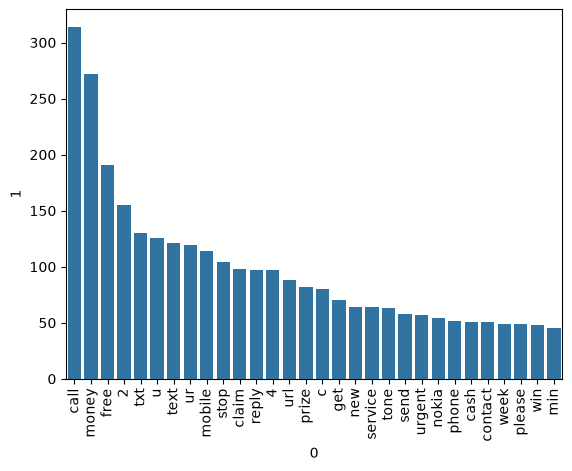

In [51]:
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [52]:
ham_corpus=[]
for msg in df[df['Target']==0]['trans_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [53]:
len(ham_corpus)

35407

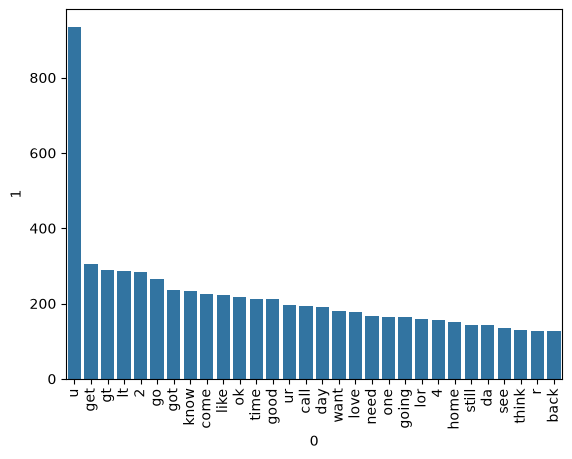

In [54]:
sns.barplot(x=pd.DataFrame(Counter(ham_corpus).most_common(30))[0],y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [55]:
df['trans_text'][1]

'ok lar joking wif u oni'

# MODEL BUILDING

In [56]:
#change text into vectors (bag of words,tf-idf,word to word)

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer(max_features=3000,min_df=2,sublinear_tf=True)

In [58]:
X=tfidf.fit_transform(df['trans_text']).toarray()

In [59]:
y=df['Target'].values

In [60]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2,stratify=y)

In [61]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score,f1_score


In [62]:
gnb=GaussianNB()
mnb=MultinomialNB()
bnb=BernoulliNB()

In [63]:
gnb.fit(X_train,y_train)
y_pred1=gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))
print('recall:',recall_score(y_test,y_pred1))
print('f1:',f1_score(y_test,y_pred1))

0.8810444874274661
[[794 109]
 [ 14 117]]
0.5176991150442478
recall: 0.8931297709923665
f1: 0.6554621848739496


In [64]:
mnb.fit(X_train,y_train)
y_pred2=mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))
print('recall:',recall_score(y_test,y_pred2))
print('f1:',f1_score(y_test,y_pred2))

0.9806576402321083
[[903   0]
 [ 20 111]]
1.0
recall: 0.8473282442748091
f1: 0.9173553719008265


In [65]:
X1 = df['trans_text']
y1 = df['Target']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X1, y1, test_size=0.2, random_state=2
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
mnb.fit(X_train, y_train)
y_pred4 = mnb.predict(X_test)
results = pd.DataFrame({
    'text': X_test_text.values,
    'actual': y_test.values,
    'predicted': y_pred4
})

false_negatives = results[
    (results['actual'] == 1) &
    (results['predicted'] == 0)
]
pd.set_option('display.max_colwidth', None)
print(false_negatives)

                                                                                                                text  \
5                              ur balance money next question complete landmark big bob barry ben text b c good luck   
19                                 romantic paris 2 night 2 flight money book 4 next year call 08704439680ts c apply   
32               call listen extreme dirty live chat going office right total privacy one know sic listening 60p min   
45                                                                      missed call alert number called left message   
73                 sm ac sptv new jersey devil detroit red wing play ice hockey correct incorrect end reply end sptv   
113             1000 girl many local 2 u r virgin 2 r ready 2 4fil ur every sexual need u 4fil text cute 69911 money   
123                      back 2 work 2morro half term u c 2nite 4 sexy passion b4 2 go back chat luv dena call money   
177                                     

In [66]:
false_negatives.iloc[1]['text']

'romantic paris 2 night 2 flight money book 4 next year call 08704439680ts c apply'

In [67]:
bnb.fit(X_train,y_train)
y_pred3=bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))
print('recall:',recall_score(y_test,y_pred3))
print('f1:',f1_score(y_test,y_pred3))

0.9854932301740812
[[896   0]
 [ 15 123]]
1.0
recall: 0.8913043478260869
f1: 0.9425287356321839


In [68]:
# checking other models

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB

In [70]:
svc=SVC(kernel='sigmoid' , gamma=1.0)
mnb=MultinomialNB()
bnb=BernoulliNB()
lrc=LogisticRegression(solver='liblinear',penalty='l1')
etc=ExtraTreesClassifier(n_estimators=50,random_state=2)

In [71]:
clfs={
    'SVC':svc,'MNB':mnb,'LR':lrc,'ETC':etc,'BNB':bnb}

In [72]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred)
    recall=recall_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)

    return accuracy,precision,recall,f1

In [73]:
train_classifier(svc,X_train,y_train,X_test,y_test)

(0.9787234042553191, 0.967741935483871, 0.8695652173913043, 0.916030534351145)

In [74]:
accuracy_scores=[]
precision_scores=[]
recall_scores=[]
f1_scores=[]
for name,clf in clfs.items():
    current_accuracy,current_precision,current_recall,current_f1=train_classifier(clf,X_train,y_train,X_test,y_test)
    print('for',name)  
    print('accuracy:',current_accuracy)
    print('precision:',current_precision)
    print('recall:',current_recall)
    print('f1:',current_f1)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)
    recall_scores.append(current_recall)
    f1_scores.append(current_f1)

for SVC
accuracy: 0.9787234042553191
precision: 0.967741935483871
recall: 0.8695652173913043
f1: 0.916030534351145
for MNB
accuracy: 0.9738878143133463
precision: 1.0
recall: 0.8043478260869565
f1: 0.891566265060241
for LR
accuracy: 0.9487427466150871
precision: 0.897196261682243
recall: 0.6956521739130435
f1: 0.7836734693877551
for ETC
accuracy: 0.9796905222437138
precision: 0.975609756097561
recall: 0.8695652173913043
f1: 0.9195402298850575
for BNB
accuracy: 0.9854932301740812
precision: 1.0
recall: 0.8913043478260869
f1: 0.9425287356321839


In [75]:
performance_df=pd.DataFrame({'Algo':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores,'Recall':recall_scores,'F1':f1_scores})
performance_df=performance_df.sort_values('F1',ascending=False).reset_index(drop=True)

In [76]:
performance_df

,Algo,Accuracy,Precision,Recall,F1
0,BNB,0.985493,1.000000,0.891304,0.942529
1,ETC,0.979691,0.975610,0.869565,0.919540
2,SVC,0.978723,0.967742,0.869565,0.916031
3,MNB,0.973888,1.000000,0.804348,0.891566
4,LR,0.948743,0.897196,0.695652,0.783673


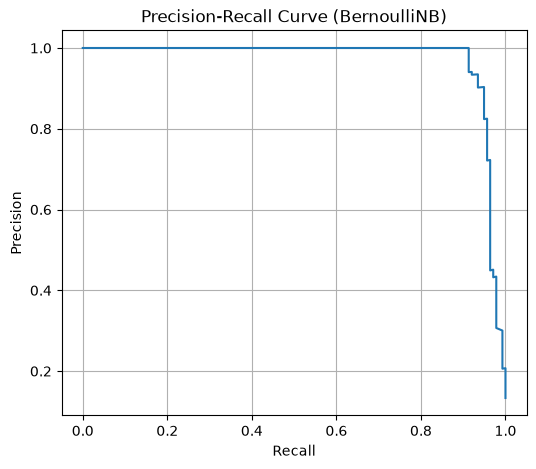

In [77]:
# precision recall curve for bernoulliNB

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

probs1 = bnb.predict_proba(X_test)[:, 1]

precision1, recall1, thresholds1 = precision_recall_curve(y_test, probs1)

plt.figure(figsize=(6,5))
plt.plot(recall1, precision1)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (BernoulliNB)")
plt.grid(True)
plt.show()

In [78]:
# threshold for bnb

threshold_df_bnb = pd.DataFrame({
    'Threshold': thresholds1,
    'Precision': precision1[:-1],
    'Recall': recall1[:-1]
})

threshold_df_bnb['F1'] = (
    2 * threshold_df_bnb['Precision'] * threshold_df_bnb['Recall']
) / (
    threshold_df_bnb['Precision'] + threshold_df_bnb['Recall']
)

print(threshold_df_bnb)

        Threshold  Precision    Recall        F1
0    2.332768e-13   0.133462  1.000000  0.235495
1    1.327418e-12   0.133591  1.000000  0.235696
2    1.895116e-12   0.133721  1.000000  0.235897
3    3.726615e-12   0.133851  1.000000  0.236099
4    6.858132e-12   0.133981  1.000000  0.236301
..            ...        ...       ...       ...
971  1.000000e+00   1.000000  0.202899  0.337349
972  1.000000e+00   1.000000  0.195652  0.327273
973  1.000000e+00   1.000000  0.188406  0.317073
974  1.000000e+00   1.000000  0.181159  0.306748
975  1.000000e+00   1.000000  0.173913  0.296296

[976 rows x 4 columns]


In [79]:
threshold_df_bnb.sort_values('F1', ascending=False).head(10)

,Threshold,Precision,Recall,F1
876,0.106159,1.000000,0.913043,0.954545
875,0.074311,0.992126,0.913043,0.950943
877,0.291280,1.000000,0.905797,0.950570
874,0.044385,0.984375,0.913043,0.947368
878,0.446814,1.000000,0.898551,0.946565
873,0.043920,0.976744,0.913043,0.943820
879,0.616373,1.000000,0.891304,0.942529
872,0.024820,0.969231,0.913043,0.940299
880,0.862531,1.000000,0.884058,0.938462
871,0.018745,0.961832,0.913043,0.936803


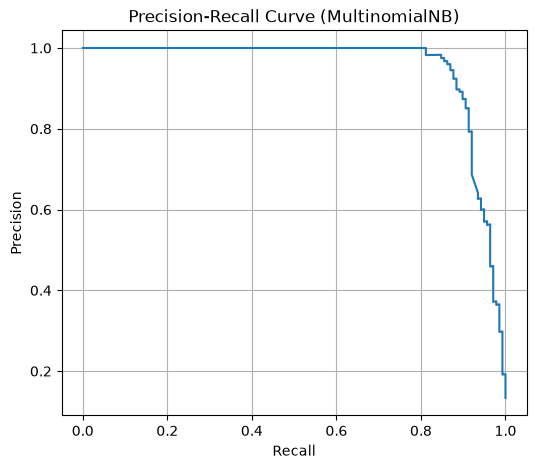

In [80]:
# precison recall curve for multinomialNB

from sklearn.metrics import precision_recall_curve
probs2=mnb.predict_proba(X_test)[:,1]
precision2,recall2,thresholds2=precision_recall_curve(y_test,probs2)
plt.figure(figsize=(6,5))
plt.plot(recall2,precision2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (MultinomialNB)')
plt.grid(True)
plt.show()

In [81]:
# threshold for multinomialNB

threshold_df_mnb = pd.DataFrame({
    'Threshold': thresholds2,
    'Precision': precision2[:-1],
    'Recall': recall2[:-1]
})

threshold_df_mnb['F1'] = (
    2 * threshold_df_mnb['Precision'] * threshold_df_mnb['Recall']
) / (
    threshold_df_mnb['Precision'] + threshold_df_mnb['Recall']
)

print(threshold_df_mnb)

      Threshold  Precision    Recall        F1
0      0.000334   0.133462  1.000000  0.235495
1      0.000592   0.133591  1.000000  0.235696
2      0.000703   0.133721  1.000000  0.235897
3      0.000706   0.133851  1.000000  0.236099
4      0.000823   0.133981  1.000000  0.236301
...         ...        ...       ...       ...
1005   0.995981   1.000000  0.036232  0.069930
1006   0.996248   1.000000  0.028986  0.056338
1007   0.996395   1.000000  0.021739  0.042553
1008   0.997057   1.000000  0.014493  0.028571
1009   0.999399   1.000000  0.007246  0.014388

[1010 rows x 4 columns]


In [82]:
threshold_df_mnb.sort_values('F1', ascending=False).head(10)

,Threshold,Precision,Recall,F1
888,0.311201,0.960000,0.869565,0.912548
890,0.320965,0.967480,0.862319,0.911877
892,0.337525,0.975207,0.855072,0.911197
894,0.352176,0.983193,0.847826,0.910506
885,0.289246,0.945312,0.876812,0.909774
887,0.302761,0.952381,0.869565,0.909091
889,0.313034,0.959677,0.862319,0.908397
891,0.333417,0.967213,0.855072,0.907692
893,0.346650,0.975000,0.847826,0.906977
884,0.283690,0.937984,0.876812,0.906367


In [83]:
# checking metrics for bernoulliNB after changing the threshold to 0.106
threshold = 0.106159
pred5 = (probs1 >= threshold).astype(int)
print("Precision:", precision_score(y_test, pred5))
print("Recall:", recall_score(y_test, pred5))
print("F1:", f1_score(y_test, pred5))

Precision: 1.0
Recall: 0.9130434782608695
F1: 0.9545454545454546


In [84]:
#picking BernoulliNB as the final model

In [85]:
import pickle 
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(bnb,open('model.pkl','wb'))

In [1]:
import os 
print(os.getcwd())

C:\Users\shelly\EMAIL SPAM CLASSIFIER
